In [42]:
import os
import pandas as pd
import janitor

janitor

import geopandas as gpd

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.colorbar import make_axes
import seaborn as sns
sns.set_theme(context="notebook", style="white", font_scale=1.2, palette="bright")
# from palettable import *
from palettable import colorbrewer

import warnings

warnings.filterwarnings("ignore")

from utilities import add_north_arrow, add_scalebar, save_mpl_fig

FP_SUBZONE_SHP2014 = os.path.join(
    "zip://",
    "..",
    "build",
    "raw-data",
    "master-plan-2014-subzone-boundary-no-sea",
    "master-plan-2014-subzone-boundary-no-sea-shp.zip",
)

In [2]:
gdf_subzones = (
    gpd.read_file(FP_SUBZONE_SHP2014)
    .to_crs("EPSG:4326")
    .clean_names()
    .assign(subzone=lambda df_: df_["subzone_n"].str.lower())
    .filter(["subzone", "geometry", "pln_area_n", "region_c"])
)
gdf_subzones

,subzone,geometry,pln_area_n,region_c
0,people's park,"POLYGON ((103.84319 1.28433, 103.84335 1.2842,...",OUTRAM,CR
1,bukit merah,"POLYGON ((103.82209 1.28049, 103.8221 1.28011,...",BUKIT MERAH,CR
2,chinatown,"POLYGON ((103.84375 1.28508, 103.844 1.28491, ...",OUTRAM,CR
3,phillip,"POLYGON ((103.84962 1.28412, 103.84955 1.28391...",DOWNTOWN CORE,CR
4,raffles place,"POLYGON ((103.85253 1.28617, 103.85253 1.28615...",DOWNTOWN CORE,CR
...,...,...,...,...
318,yew tee,"POLYGON ((103.7466 1.40541, 103.74691 1.4054, ...",CHOA CHU KANG,WR
319,pasir ris wafer fab park,"POLYGON ((103.93478 1.40099, 103.93625 1.39957...",PASIR RIS,ER
320,matilda,"POLYGON ((103.90506 1.39996, 103.90358 1.39687...",PUNGGOL,NER
321,north coast,"POLYGON ((103.77664 1.45145, 103.77673 1.4515,...",WOODLANDS,NR


In [3]:
df = (
    pd.read_csv("../build/cd-panel-labels.csv", low_memory=False)
    .rename_column("home", "subzone")
    .drop_duplicates(["subzone"], ignore_index=True)
    # ==============
    .assign(
        wpsm_ptile=lambda df_: df_["wpsm_home"].rank(method="max", pct=True).mul(100),
        wpsm_qtile=lambda df_: (
            (df_["wpsm_ptile"] // 25).clip(0, 3).add(1).astype("Int8")
        ),
    )
)

df.head()

,date,subzone,inflow,basecount,dest_basecount,area,pa_home,htype_home,resident_count_home,private_home,...,private_psm_dest,private_price_dest,wpsm_private_home,wpsm_public_home,wpsm_home,wpsm_private_dest,wpsm_public_dest,wpsm_dest,wpsm_ptile,wpsm_qtile
0,2020-01-01,admiralty,14.583333,48,24,admiralty,Sembawang,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,14110,0.000000,...,NaN,NaN,NaN,3930.897154,3930.897154,NaN,3930.897154,3930.897154,6.481481,1
1,2020-01-01,airport road,9.090909,11,25,airport road,Paya Lebar,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
2,2020-01-01,alexandra hill,37.837838,370,359,alexandra hill,Bukit Merah,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,13350,0.000000,...,NaN,NaN,NaN,5493.879995,5493.879995,NaN,5493.879995,5493.879995,33.796296,2
3,2020-01-01,alexandra north,7.563025,119,359,alexandra hill,Bukit Merah,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,2120,100.000000,...,NaN,NaN,18564.409277,NaN,18564.409277,NaN,5493.879995,5493.879995,88.425926,4
4,2020-01-01,aljunied,0.161987,1852,359,alexandra hill,Geylang,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,38930,31.826355,...,NaN,NaN,4500.487891,3900.477008,8400.964898,NaN,5493.879995,5493.879995,58.796296,3


In [4]:
gdf = gdf_subzones.merge(df, on="subzone", how="right", validate="1:1")
gdf.head()

,subzone,geometry,pln_area_n,region_c,date,inflow,basecount,dest_basecount,area,pa_home,...,private_psm_dest,private_price_dest,wpsm_private_home,wpsm_public_home,wpsm_home,wpsm_private_dest,wpsm_public_dest,wpsm_dest,wpsm_ptile,wpsm_qtile
0,admiralty,"POLYGON ((103.82855 1.45878, 103.82871 1.45854...",SEMBAWANG,NR,2020-01-01,14.583333,48,24,admiralty,Sembawang,...,NaN,NaN,NaN,3930.897154,3930.897154,NaN,3930.897154,3930.897154,6.481481,1
1,airport road,"POLYGON ((103.90143 1.35617, 103.9012 1.35572,...",PAYA LEBAR,ER,2020-01-01,9.090909,11,25,airport road,Paya Lebar,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
2,alexandra hill,"POLYGON ((103.81445 1.28547, 103.81433 1.28501...",BUKIT MERAH,CR,2020-01-01,37.837838,370,359,alexandra hill,Bukit Merah,...,NaN,NaN,NaN,5493.879995,5493.879995,NaN,5493.879995,5493.879995,33.796296,2
3,alexandra north,"POLYGON ((103.81743 1.29431, 103.81787 1.29393...",BUKIT MERAH,CR,2020-01-01,7.563025,119,359,alexandra hill,Bukit Merah,...,NaN,NaN,18564.409277,NaN,18564.409277,NaN,5493.879995,5493.879995,88.425926,4
4,aljunied,"POLYGON ((103.89127 1.32132, 103.89153 1.32014...",GEYLANG,CR,2020-01-01,0.161987,1852,359,alexandra hill,Geylang,...,NaN,NaN,4500.487891,3900.477008,8400.964898,NaN,5493.879995,5493.879995,58.796296,3


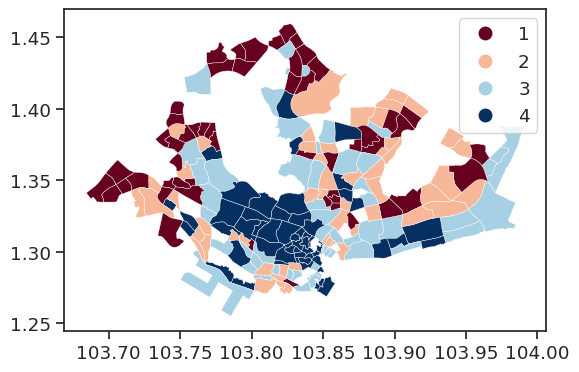

In [5]:
# plot
_, ax = plt.subplots(figsize=(6, 4))
gdf.query("resident_count_home>0").plot(
    column="wpsm_qtile",
    categorical=True,
    cmap="RdBu",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    ax=ax,
)
plt.tight_layout()

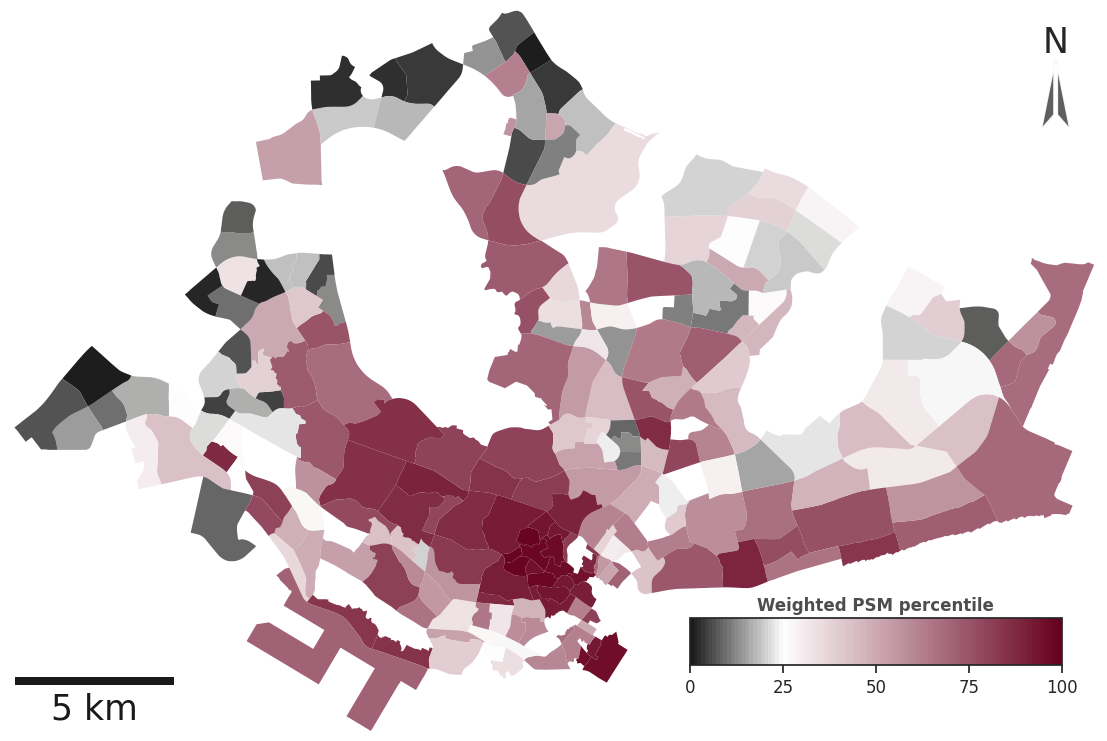

In [95]:
# plot
# Create custom cmap
base_cmap = plt.cm.get_cmap("RdBu")
# base_cmap = cmocean.diverging.Curl_20_r.get_mpl_colormap()
# base_cmap = cmocean.diverging.Delta_20_r.get_mpl_colormap()
# base_cmap = colorbrewer.diverging.PRGn_11_r.get_mpl_colormap()
base_cmap = colorbrewer.diverging.RdGy_11_r.get_mpl_colormap()
# base_cmap = lightbartlein.diverging.BlueDarkOrange18_18_r.get_mpl_colormap()
# base_cmap = lightbartlein.diverging.BlueGray_8_r.get_mpl_colormap()

# base_cmap = lightbartlein.diverging.GreenMagenta_16.get_mpl_colormap()
# base_cmap = scientific.diverging.Lisbon_20.get_mpl_colormap()

split = 25  # where the hue switch should be
asym_cmap = LinearSegmentedColormap.from_list(
    "custom_asym",
    [(0.0, base_cmap(0.00)), (split / 100.0, base_cmap(0.50)), (1.0, base_cmap(1.00))],
    N=100,
)

norm = mcolors.Normalize(vmin=0, vmax=100)

# Init plot
fig, ax = plt.subplots(figsize=(12, 8))
gdf.query("resident_count_home>0").plot(
    column="wpsm_ptile",
    cmap=asym_cmap,
    norm=norm,
    edgecolor="none",
    linewidth=0.3,
    alpha=0.99,
    legend=False,
    ax=ax,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)

# Compose Color bar
sm = ScalarMappable(norm=norm, cmap=asym_cmap)
sm.set_array([])
axins, kw = make_axes(
    ax,
    location="bottom",
    fraction=0.9,
    shrink=0.40,
    aspect=8,
    pad=0.12,
    anchor=(1.05, 0),
)
cbar = fig.colorbar(sm, cax=axins, **kw)
cbar.set_ticks([0, split, 50, 75, 100])
cbar.set_ticklabels([0, 25, 50, 75, 100])
cbar.ax.tick_params(labelsize=12)

cbar.ax.set_title(
    "Weighted PSM percentile",
    fontsize=12,
    pad=6,
    loc="center",
    color=".3",
    fontweight="bold",
)

# axis settings
ax.set_xlim(103.683, 103.992)
ax.set_ylim(1.255, 1.460)
add_north_arrow(ax=ax, x=103.98, y=1.445, fontsize=25)
add_scalebar(ax=ax, location="lower left", fontsize=25)
plt.tight_layout()
ax.set_axis_off()

save_mpl_fig("../results/figures/supplementary/lower-vs-higher-ptiles")